# Demanda eléctrica por área del SEIN: la prueba de 2026

**TB1 · Metodología para Data Science (1ACC0240) · UPC · ciclo 2026-2 · Grupo 3**

Notebook 03 de CRISP-DM para el caso peruano: **evaluación en la prueba fuera de distribución**, de enero a octubre de
2026, con El Niño Costero extraordinario (el ICEN llegó a 3.98 en agosto). Es el resultado central del paper.

**Reglas de esta corrida** (spec §8.1):

- **Aquí no se elige nada.** El modelo (Random Forest por área), sus hiperparámetros, las variantes de exógenas y las
  políticas de reentrenamiento salen del [notebook 02](02_sein_modelado_evaluacion.ipynb), elegidos en 2025. Como
  alternativa se reporta el XGBoost global, que empató con él en 2025.
- **Las hipótesis se escribieron antes de mirar 2026** (notebook 02, §12) y se evalúan tal como están, en la §9.
- **Se corre una sola vez.** Si algo falla a mitad de camino se corrige el código, no la elección.

| Paso | Qué hace |
|---|---|
| 1. Datos | Los datasets de 2016 a octubre de 2026, con la prueba incluida |
| 2. Referencias ingenuas en 2026 | La vara de la prueba: la mejor de las tres en cada área y horizonte |
| 3. El modelo fijo frente a las referencias | Entrenado hasta 2025, sin tocarlo durante 2026 (política A) |
| 4. Ablación de exógenas en 2026 | M0 a M3 con el modelo fijo |
| 5. Experimento de adaptación | Fijo frente a reentrenado cada semana, con y sin exógenas, y con la alerta de ENFEN |
| 6. Mes a mes | Cómo cambia el error a medida que El Niño se intensifica |
| 7. Regímenes | Categoría de El Niño, horas de mayor demanda y días con temperatura fuera de lo visto |
| 8. Diagnóstico | Real contra predicho en el pico de El Niño |
| 9. Las hipótesis, una por una | Se cumplen o no, con su evidencia |
| 10. Guardar | Predicciones y tablas para la app y el paper |

Corre en Colab en unas 3 horas (el Random Forest se reentrena cada semana en la CPU). Las predicciones de cada
bloque se guardan en `cache/prueba_2026/` apenas terminan: si la sesión se cae, se relanza y retoma desde ahí. Con `TPF_RAPIDO=1` corre en
minutos, pero **solo con datos sintéticos**: con los datos reales mostraría la prueba antes de tiempo.

# Configuración

In [1]:
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and "TETOUAN_DATA" not in os.environ:
    RAMA = "develop"
    !pip install -q "git+https://github.com/R0SEWT/tetouan-power-forecast@{RAMA}"
    from tetouan_power_forecast.medallon import usar_drive
    usar_drive()
elif not EN_COLAB:
    os.environ.setdefault("TETOUAN_DATA", str(Path.cwd().parent / "data"))

In [2]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import r2_score

from tetouan_power_forecast.coes import cargar_demanda_areas
from tetouan_power_forecast.evaluacion import bootstrap_diferencia_mae, errores, hora_objetivo, mae_por_grupo
from tetouan_power_forecast.exogenas import icen_disponible
from tetouan_power_forecast.medallon import raiz_datos
from tetouan_power_forecast.modelado_sein import (
    VARIANTES_ABLACION,
    bloques,
    categoria_icen,
    en,
    es_hora_pico,
    gradient_boosting_global,
    horas_mayor_demanda,
    mejor_referencia,
    predecir_global,
    predecir_local,
    predecir_por_bloques,
    preparar_datasets,
    random_forest,
    subestimacion_sobre_p90,
    tramo,
)
from tetouan_power_forecast.modelos import ModeloRazon
from tetouan_power_forecast.variables_sein import AREAS, HORIZONTES, PASO, REFERENCIAS

RAIZ = raiz_datos()
RAPIDO = os.environ.get("TPF_RAPIDO") == "1"  # solo con datos sintéticos
SEMILLA = 0
FRECUENCIA_REENTRENO = "MS" if RAPIDO else "W-MON"  # cada lunes a las 00:00, como en 2025
INICIO_PRUEBA = pd.Timestamp("2026-01-01")
NOMBRES = {a: a.capitalize() for a in AREAS}
NOMBRES_REF = {"persistencia": "Persistencia", "ayer": "Ayer", "semana_pasada": "Semana pasada"}
COLORES = {"NORTE": "#E69F00", "CENTRO": "#0072B2", "SUR": "#009E73"}
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", message=".*mismatched devices.*")

# Lo elegido en 2025 en el notebook 02. No se cambia aquí.
ELEGIDO = "Random Forest por área"
ALTERNATIVO = "Gradient Boosting global"
HIPERPARAMETROS = {
    ELEGIDO: {"n_estimators": 100, "min_samples_leaf": 5, "max_samples": 0.3, "max_features": 0.3, "max_depth": 20},
    ALTERNATIVO: {"colsample_bytree": 0.7, "learning_rate": 0.0358, "max_depth": 10, "min_child_weight": 20,
                  "n_estimators": 800, "reg_lambda": 1.0, "subsample": 0.85},
}
MODELOS = {
    ELEGIDO: ModeloRazon(random_forest(SEMILLA, **HIPERPARAMETROS[ELEGIDO])),
    ALTERNATIVO: gradient_boosting_global(SEMILLA, **HIPERPARAMETROS[ALTERNATIVO]),
}
metadatos_02 = RAIZ / "modelos" / "sein" / "modelo_final.json"
if metadatos_02.exists():  # el modelo y los hiperparámetros tienen que ser los del notebook 02
    guardado = json.loads(metadatos_02.read_text())
    assert guardado["modelo"] == ELEGIDO, guardado["modelo"]
    assert guardado["hiperparametros"] == HIPERPARAMETROS[ELEGIDO], guardado["hiperparametros"]
    print("Modelo e hiperparámetros verificados contra el notebook 02")
else:
    print("Sin modelo_final.json: se usan los hiperparámetros escritos arriba")
print("Elegido:", ELEGIDO, "· alternativa:", ALTERNATIVO, "· RAPIDO =", RAPIDO)

Modelo e hiperparámetros verificados contra el notebook 02
Elegido: Random Forest por área · alternativa: Gradient Boosting global · RAPIDO = False


# 1. Datos

Los mismos datasets del notebook 02 (`preparar_datasets`, con la regla de información), ahora con la prueba
incluida. Entrenamiento 2016-2024, validación 2025 y prueba 2026, con un hueco de H pasos antes de cada corte. El
modelo fijo se entrena con entrenamiento y validación ("desarrollo") y no se toca durante 2026.

In [3]:
demanda = cargar_demanda_areas()
silver_exo = RAIZ / "exogenas" / "silver"
exogenas = {
    "temperatura": pd.read_parquet(silver_exo / "temperatura_areas.parquet"),
    "icen": pd.read_parquet(silver_exo / "icen.parquet"),
    "nino12": pd.read_parquet(silver_exo / "nino12_semanal.parquet"),
    "eventos": pd.read_parquet(silver_exo / "eventos_coes.parquet"),
}
try:
    import holidays
    FERIADOS = list(holidays.PE(years=range(2016, 2027)))
except ImportError:
    FERIADOS = []
    print("sin el paquete holidays: los feriados quedan en cero")

datos, filas = {}, []
for nombre_h, h in HORIZONTES.items():
    locales, global_ = preparar_datasets(demanda, h, variantes=VARIANTES_ABLACION, feriados=FERIADOS, **exogenas)
    datos[nombre_h] = {"locales": locales, "global": global_}
    for a in AREAS:
        conteo = locales[a]["particion"].value_counts()
        prueba = tramo(locales[a], "prueba")
        filas.append({"Horizonte": nombre_h, "Área": NOMBRES[a], "Desarrollo": len(tramo(locales[a], "desarrollo")),
                      "Prueba": conteo.get("prueba", 0), "Prueba desde": prueba["DateTime"].min(),
                      "Prueba hasta": prueba["DateTime"].max()})
display(pd.DataFrame(filas).set_index(["Horizonte", "Área"]))


def ajustar_y_predecir(nombre_h, columnas, entrenar, evaluar, metodo=ELEGIDO):
    # Predicciones por área de un método entrenado y evaluado en las filas indicadas
    if metodo.endswith("global"):
        return predecir_global(MODELOS[metodo], datos[nombre_h]["global"], columnas, entrenar, evaluar)
    return predecir_local(MODELOS[metodo], datos[nombre_h]["locales"], columnas, entrenar, evaluar)


def prueba(nombre_h, a):
    return tramo(datos[nombre_h]["locales"][a], "prueba")


CACHE = RAIZ / "cache" / ("prueba_2026_rapido" if RAPIDO else "prueba_2026")
CACHE.mkdir(parents=True, exist_ok=True)


def con_cache(nombre, calcular):
    # Guarda las predicciones de cada bloque apenas terminan. Si la sesión de Colab se cae, la corrida se relanza
    # con la misma carpeta y retoma desde aquí; no cambia ningún cálculo (todo es determinista con la semilla).
    ruta = CACHE / f"{nombre}.npz"
    if ruta.exists():
        guardado = np.load(ruta)
        return {a: guardado[a] for a in AREAS}
    pred = calcular()
    temporal = ruta.with_name(ruta.stem + ".tmp.npz")
    np.savez(temporal, **{a: np.asarray(p, dtype=float) for a, p in pred.items()})
    temporal.replace(ruta)
    return pred


print("Caché de la corrida en", CACHE, "·", len(list(CACHE.glob("*.npz"))), "bloques ya calculados")

Desarrollo  Prueba Prueba desde        Prueba hasta
Horizonte Área                                                       
1h        Norte       172311   13920   2026-01-01 2026-10-17 23:30:00
          Centro      172311   13920   2026-01-01 2026-10-17 23:30:00
          Sur         172311   13920   2026-01-01 2026-10-17 23:30:00
24h       Norte       171943   13871   2026-01-01 2026-10-16 23:00:00
          Centro      171943   13871   2026-01-01 2026-10-16 23:00:00
          Sur         171943   13871   2026-01-01 2026-10-16 23:00:00

Caché de la corrida en /content/datos/cache/prueba_2026 · 19 bloques ya calculados


# 2. Referencias ingenuas en 2026

Persistencia, ayer y semana pasada a la misma hora. El modelo se compara con **la mejor de las tres en la prueba**,
en cada área y horizonte (spec §8.2).

In [4]:
filas = []
for nombre_h in HORIZONTES:
    for a in AREAS:
        t = prueba(nombre_h, a)
        for ref in REFERENCIAS:
            e = errores(t["real"], t[ref])
            filas.append({"Horizonte": nombre_h, "Área": NOMBRES[a], "Referencia": NOMBRES_REF[ref],
                          "MAE (MW)": e["MAE (kW)"], "MAPE (%)": e["MAPE (%)"]})
display(pd.DataFrame(filas).pivot_table(index=["Horizonte", "Referencia"], columns="Área",
                                        values=["MAE (MW)", "MAPE (%)"]).round(2))
MEJOR_REF = {h: {a: mejor_referencia(prueba(h, a)) for a in AREAS} for h in HORIZONTES}
for h in HORIZONTES:
    print(f"Mejor referencia en 2026 a {h}:", {NOMBRES[a]: NOMBRES_REF[r] for a, r in MEJOR_REF[h].items()})


def ref_mejor(nombre_h, a):
    return prueba(nombre_h, a)[MEJOR_REF[nombre_h][a]].to_numpy()

MAE (MW)               MAPE (%)            
Área                      Centro  Norte    Sur   Centro Norte   Sur
Horizonte Referencia                                               
1h        Ayer            212.53  57.61  54.97     4.95  5.14  3.05
          Persistencia    128.51  41.77  31.62     2.98  3.67  1.74
          Semana pasada   135.36  44.28  81.49     3.12  3.93  4.54
24h       Ayer            211.06  57.18  54.83     4.90  5.09  3.04
          Persistencia    211.06  57.18  54.83     4.90  5.09  3.04
          Semana pasada   135.27  44.23  81.69     3.12  3.92  4.55

Mejor referencia en 2026 a 1h: {'Norte': 'Persistencia', 'Centro': 'Persistencia', 'Sur': 'Persistencia'}
Mejor referencia en 2026 a 24h: {'Norte': 'Semana pasada', 'Centro': 'Semana pasada', 'Sur': 'Persistencia'}


# 3. El modelo fijo frente a las referencias

El modelo elegido, entrenado hasta 2025 y sin reentrenar en 2026 (política A, M0). Se reporta también el XGBoost
global. La diferencia de MAE con la mejor referencia va con su intervalo al 95 % por *bootstrap* de días.

In [5]:
inicio = time.time()
fijo = {h: {v: con_cache(f"fijo_{h}_{v}", lambda h=h, v=v: ajustar_y_predecir(h, v, en("desarrollo"), en("prueba")))
            for v in VARIANTES_ABLACION} for h in HORIZONTES}
alternativo = {h: con_cache(f"alternativo_{h}", lambda h=h: ajustar_y_predecir(h, "M0", en("desarrollo"), en("prueba"),
                                                                              metodo=ALTERNATIVO)) for h in HORIZONTES}
print(f"{(time.time() - inicio) / 60:.1f} min")

filas = []
for h in HORIZONTES:
    for a in AREAS:
        t = prueba(h, a)
        mae_ref = errores(t["real"], ref_mejor(h, a))["MAE (kW)"]
        for metodo, pred in [(f"Mejor referencia ({NOMBRES_REF[MEJOR_REF[h][a]]})", ref_mejor(h, a)),
                             (f"{ELEGIDO}, fijo (A)", fijo[h]["M0"][a]), (f"{ALTERNATIVO}, fijo", alternativo[h][a])]:
            e = errores(t["real"], pred)
            fila = {"Horizonte": h, "Área": NOMBRES[a], "Método": metodo, "MAE (MW)": e["MAE (kW)"],
                    "RMSE (MW)": e["RMSE (kW)"], "MAPE (%)": e["MAPE (%)"], "R²": r2_score(t["real"], pred),
                    "Mejora vs. mejor referencia (%)": 100 * (1 - e["MAE (kW)"] / mae_ref)}
            if not metodo.startswith("Mejor"):
                dif, bajo, alto = bootstrap_diferencia_mae(t["real"], pred, ref_mejor(h, a), t["DateTime"], semilla=SEMILLA)
                fila.update({"Δ MAE vs. referencia (MW)": dif, "IC 95 % bajo": bajo, "IC 95 % alto": alto})
            filas.append(fila)
frente_referencias = pd.DataFrame(filas)
display(frente_referencias.set_index(["Horizonte", "Área", "Método"]).round(2))

0.0 min


MAE (MW)  RMSE (MW)  MAPE (%)    R²  Mejora vs. mejor referencia (%)  Δ MAE vs. referencia (MW)  IC 95 % bajo  IC 95 % alto
Horizonte Área   Método                                                                                                                                                       
1h        Norte  Mejor referencia (Persistencia)      41.77      53.06      3.67  0.83                             0.00                        NaN           NaN           NaN
                 Random Forest por área, fijo (A)     20.15      26.12      1.79  0.96                            51.75                     -21.61        -22.14        -21.13
                 Gradient Boosting global, fijo       19.87      25.90      1.77  0.96                            52.43                     -21.90        -22.42        -21.40
          Centro Mejor referencia (Persistencia)     128.51     164.29      2.98  0.88                             0.00                        NaN           NaN           NaN
                 Random Forest por área, fijo (A)     54.05      70.23      1.25  0.98                            57.94                     -74.45        -75.89        -72.92
                 Gradient Boosting global, fijo       53.40      68.93      1.24  0.98                            58.45                     -75.11        -76.59        -73.57
          Sur    Mejor referencia (Persistencia)      31.62      43.45      1.74  0.80                             0.00                        NaN           NaN           NaN
                 Random Forest por área, fijo (A)     22.43      33.73      1.24  0.88                            29.07                      -9.19         -9.62         -8.75
                 Gradient Boosting global, fijo       22.39      33.96      1.24  0.88                            29.19                      -9.23         -9.69         -8.72
24h       Norte  Mejor referencia (Semana pasada)     44.23      59.01      3.92  0.79                             0.00                        NaN           NaN           NaN
                 Random Forest por área, fijo (A)     28.97      37.94      2.58  0.91                            34.51                     -15.26        -18.09        -12.69
                 Gradient Boosting global, fijo       29.27      38.43      2.60  0.91                            33.82                     -14.96        -17.91        -12.28
          Centro Mejor referencia (Semana pasada)    135.27     207.21      3.12  0.81                             0.00                        NaN           NaN           NaN
                 Random Forest por área, fijo (A)     78.15     102.68      1.80  0.95                            42.23                     -57.13        -71.26        -45.30
                 Gradient Boosting global, fijo       79.99     104.79      1.84  0.95                            40.87                     -55.28        -69.48        -43.59
          Sur    Mejor referencia (Persistencia)      54.83      76.57      3.04  0.38                             0.00                        NaN           NaN           NaN
                 Random Forest por área, fijo (A)     48.28      66.29      2.68  0.54                            11.95                      -6.55         -8.87         -4.36
                 Gradient Boosting global, fijo       48.89      67.22      2.71  0.53                            10.82                      -5.93         -8.37         -3.62

# 4. Ablación de exógenas en 2026

Con el modelo fijo: M0 (demanda y calendario), M1 (+ clima), M2 (+ El Niño) y M3 (+ fallas en curso). Las fallas se
mantienen definidas como en 2025 para poder comparar con la validación, y por eso se reporta también M2, que no las
lleva.

In [6]:
CONTRASTES_ABLACION = [("M1", "M0", "Clima (M1 − M0)"), ("M2", "M1", "El Niño (M2 − M1)"),
                       ("M3", "M2", "Fallas (M3 − M2)"), ("M3", "M0", "Todas (M3 − M0)"), ("M2", "M0", "Sin fallas (M2 − M0)")]
filas = []
for h in HORIZONTES:
    for a in AREAS:
        t = prueba(h, a)
        for nuevo, base, nombre in CONTRASTES_ABLACION:
            dif, bajo, alto = bootstrap_diferencia_mae(t["real"], fijo[h][nuevo][a], fijo[h][base][a], t["DateTime"],
                                                       semilla=SEMILLA)
            filas.append({"Horizonte": h, "Contraste": nombre, "Área": NOMBRES[a], "Δ MAE (MW)": dif,
                          "IC 95 % bajo": bajo, "IC 95 % alto": alto, "Distinguible": not (bajo <= 0 <= alto)})
ablacion = pd.DataFrame(filas)
display(pd.DataFrame({v: {(h, NOMBRES[a]): errores(prueba(h, a)["real"], fijo[h][v][a])["MAE (kW)"]
                          for h in HORIZONTES for a in AREAS} for v in VARIANTES_ABLACION}).round(2)
        .style.set_caption("MAE (MW) en 2026 del modelo fijo, por variante"))
display(ablacion.set_index(["Horizonte", "Contraste", "Área"]).round(2))

Δ MAE (MW)  IC 95 % bajo  IC 95 % alto  Distinguible
Horizonte Contraste            Área                                                        
1h        Clima (M1 − M0)      Norte        -0.09         -0.18          0.01         False
          El Niño (M2 − M1)    Norte        -0.00         -0.06          0.05         False
          Fallas (M3 − M2)     Norte        -0.01         -0.05          0.04         False
          Todas (M3 − M0)      Norte        -0.10         -0.19          0.00         False
          Sin fallas (M2 − M0) Norte        -0.09         -0.18          0.01         False
          Clima (M1 − M0)      Centro       -0.46         -0.71         -0.20          True
          El Niño (M2 − M1)    Centro       -0.09         -0.25          0.06         False
          Fallas (M3 − M2)     Centro        0.02         -0.11          0.16         False
          Todas (M3 − M0)      Centro       -0.53         -0.78         -0.27          True
          Sin fallas (M2 − M0) Centro       -0.55         -0.82         -0.30          True
          Clima (M1 − M0)      Sur           0.04         -0.03          0.11         False
          El Niño (M2 − M1)    Sur          -0.02         -0.09          0.06         False
          Fallas (M3 − M2)     Sur          -0.04         -0.11          0.02         False
          Todas (M3 − M0)      Sur          -0.02         -0.11          0.06         False
          Sin fallas (M2 − M0) Sur           0.02         -0.06          0.11         False
24h       Clima (M1 − M0)      Norte         0.42          0.16          0.68          True
          El Niño (M2 − M1)    Norte        -0.03         -0.19          0.09         False
          Fallas (M3 − M2)     Norte        -0.13         -0.22         -0.04          True
          Todas (M3 − M0)      Norte         0.25          0.03          0.48          True
          Sin fallas (M2 − M0) Norte         0.39          0.14          0.62          True
          Clima (M1 − M0)      Centro        1.35          0.10          2.97          True
          El Niño (M2 − M1)    Centro       -0.01         -0.48          0.44         False
          Fallas (M3 − M2)     Centro        0.14         -0.20          0.48         False
          Todas (M3 − M0)      Centro        1.48          0.24          3.03          True
          Sin fallas (M2 − M0) Centro        1.34          0.19          2.74          True
          Clima (M1 − M0)      Sur           0.02         -0.28          0.32         False
          El Niño (M2 − M1)    Sur           0.83          0.46          1.23          True
          Fallas (M3 − M2)     Sur          -0.08         -0.31          0.16         False
          Todas (M3 − M0)      Sur           0.77          0.32          1.25          True
          Sin fallas (M2 − M0) Sur           0.85          0.44          1.30          True

# 5. Experimento de adaptación

Las mismas políticas que en 2025 (spec §8.4), ahora durante El Niño extraordinario:

| | Sin exógenas (M0) | Con exógenas (M3) |
|---|---|---|
| **Modelo fijo** | A | B |
| **Reentrenado cada semana** | C | D |

Más reentrenar cuando cambia la categoría del ICEN que ya se conocía (la alerta de ENFEN), sola y sumada a la
semanal, y la variante M2 (sin fallas) fija y semanal. Ventana creciente, hiperparámetros congelados y un hueco de H
pasos antes de cada reentrenamiento.

In [7]:
POLITICAS = {"fijo": "fijo", "semanal": "periodica", "alerta ENFEN": "alerta", "semanal + alerta": "periodica+alerta"}
VARIANTES_POLITICA = {"fijo": ["M0", "M2", "M3"], "semanal": ["M0", "M2", "M3"], "alerta ENFEN": ["M0", "M3"],
                      "semanal + alerta": ["M0", "M3"]}
adaptacion, pred_adaptacion = [], {}
for h, pasos in HORIZONTES.items():
    inicio = time.time()
    fechas_prueba = tramo(datos[h]["global"], "prueba")["DateTime"].drop_duplicates().sort_values()
    alerta = categoria_icen(icen_disponible(fechas_prueba, exogenas["icen"]))
    pred_adaptacion[h] = {}
    for nombre_p, politica in POLITICAS.items():
        cortes = bloques(fechas_prueba, politica, frecuencia=FRECUENCIA_REENTRENO, alerta=alerta)
        for v in VARIANTES_POLITICA[nombre_p]:
            if nombre_p == "fijo":
                pred = fijo[h][v]  # ya calculado en la §3: un solo bloque, entrenado hasta el hueco
            else:
                nombre_cache = f"{nombre_p}_{h}_{v}".replace(" + ", "_mas_").replace(" ", "_")
                pred = con_cache(nombre_cache, lambda h=h, v=v, cortes=cortes, pasos=pasos: predecir_por_bloques(
                    lambda e, s: ajustar_y_predecir(h, v, e, s), cortes, pasos * PASO, seleccionar=en("prueba")))
            pred_adaptacion[h][(nombre_p, v)] = pred
            for a in AREAS:
                t = prueba(h, a)
                e = errores(t["real"], pred[a])
                adaptacion.append({"Horizonte": h, "Política": nombre_p, "Variante": v, "Área": NOMBRES[a],
                                   "Reentrenamientos": len(cortes) - 1, "MAE (MW)": e["MAE (kW)"],
                                   "MAPE (%)": e["MAPE (%)"],
                                   "Mejora vs. mejor referencia (%)": 100 * (1 - e["MAE (kW)"] / errores(t["real"], ref_mejor(h, a))["MAE (kW)"])})
        print(f"{h} · {nombre_p}: {len(cortes) - 1} reentrenamientos · {(time.time() - inicio) / 60:.1f} min", flush=True)
adaptacion = pd.DataFrame(adaptacion)
display(adaptacion.pivot_table(index=["Horizonte", "Variante", "Política"], columns="Área",
                               values=["MAE (MW)", "Mejora vs. mejor referencia (%)"]).round(2))

1h · fijo: 0 reentrenamientos · 0.0 min


1h · semanal: 41 reentrenamientos · 0.0 min


1h · alerta ENFEN: 4 reentrenamientos · 0.0 min


1h · semanal + alerta: 43 reentrenamientos · 0.0 min


24h · fijo: 0 reentrenamientos · 0.0 min


24h · semanal: 41 reentrenamientos · 17.0 min


24h · alerta ENFEN: 4 reentrenamientos · 20.6 min


24h · semanal + alerta: 43 reentrenamientos · 52.3 min


MAE (MW)               Mejora vs. mejor referencia (%)              
Área                                  Centro  Norte    Sur                          Centro  Norte    Sur
Horizonte Variante Política                                                                             
1h        M0       alerta ENFEN        53.91  20.08  22.32                           58.05  51.92  29.40
                   fijo                54.05  20.15  22.43                           57.94  51.75  29.07
                   semanal             53.62  20.02  22.34                           58.27  52.08  29.35
                   semanal + alerta    53.64  20.02  22.34                           58.26  52.07  29.36
          M2       fijo                53.50  20.06  22.45                           58.37  51.96  28.99
                   semanal             52.80  19.86  22.29                           58.91  52.46  29.51
          M3       alerta ENFEN        53.13  19.94  22.29                           58.66  52.27  29.50
                   fijo                53.52  20.06  22.41                           58.35  51.98  29.13
                   semanal             52.92  19.89  22.20                           58.82  52.38  29.80
                   semanal + alerta    52.94  19.89  22.20                           58.80  52.39  29.79
24h       M0       alerta ENFEN        78.13  28.97  48.08                           42.25  34.51  12.31
                   fijo                78.15  28.97  48.28                           42.23  34.51  11.95
                   semanal             78.10  28.98  48.14                           42.27  34.47  12.21
                   semanal + alerta    78.12  28.98  48.13                           42.25  34.47  12.22
          M2       fijo                79.49  29.35  49.13                           41.24  33.64  10.39
                   semanal             78.78  29.19  48.48                           41.77  34.01  11.59
          M3       alerta ENFEN        79.10  29.16  48.66                           41.53  34.06  11.26
                   fijo                79.63  29.22  49.05                           41.14  33.94  10.53
                   semanal             78.75  29.15  48.48                           41.78  34.10  11.57
                   semanal + alerta    78.74  29.15  48.48                           41.80  34.10  11.58

In [8]:
CONTRASTES_ADAPTACION = {
    "Reentrenar sin exógenas (C − A)": (("semanal", "M0"), ("fijo", "M0")),
    "Reentrenar con exógenas (D − B)": (("semanal", "M3"), ("fijo", "M3")),
    "Reentrenar sin fallas (semanal M2 − fijo M2)": (("semanal", "M2"), ("fijo", "M2")),
    "Exógenas con reentrenamiento (D − C)": (("semanal", "M3"), ("semanal", "M0")),
    "Alerta en vez de semanal (alerta − semanal, M3)": (("alerta ENFEN", "M3"), ("semanal", "M3")),
    "Alerta además de semanal (semanal + alerta − semanal, M3)": (("semanal + alerta", "M3"), ("semanal", "M3")),
}
filas = []
for h in HORIZONTES:
    p = pred_adaptacion[h]
    for nombre, (nuevo, base) in CONTRASTES_ADAPTACION.items():
        for a in AREAS:
            t = prueba(h, a)
            dif, bajo, alto = bootstrap_diferencia_mae(t["real"], p[nuevo][a], p[base][a], t["DateTime"], semilla=SEMILLA)
            filas.append({"Horizonte": h, "Contraste": nombre, "Área": NOMBRES[a], "Δ MAE (MW)": dif,
                          "IC 95 % bajo": bajo, "IC 95 % alto": alto, "Distinguible": not (bajo <= 0 <= alto)})
efectos_adaptacion = pd.DataFrame(filas)
display(efectos_adaptacion.set_index(["Horizonte", "Contraste", "Área"]).round(2))

Δ MAE (MW)  IC 95 % bajo  IC 95 % alto  Distinguible
Horizonte Contraste                                          Área                                                        
1h        Reentrenar sin exógenas (C − A)                    Norte        -0.14         -0.19         -0.09          True
                                                             Centro       -0.43         -0.56         -0.29          True
                                                             Sur          -0.09         -0.15         -0.03          True
          Reentrenar con exógenas (D − B)                    Norte        -0.17         -0.23         -0.11          True
                                                             Centro       -0.60         -0.78         -0.42          True
                                                             Sur          -0.21         -0.29         -0.14          True
          Reentrenar sin fallas (semanal M2 − fijo M2)       Norte        -0.21         -0.28         -0.14          True
                                                             Centro       -0.70         -0.86         -0.53          True
                                                             Sur          -0.16         -0.23         -0.09          True
          Exógenas con reentrenamiento (D − C)               Norte        -0.13         -0.21         -0.03          True
                                                             Centro       -0.70         -0.94         -0.45          True
                                                             Sur          -0.14         -0.22         -0.07          True
          Alerta en vez de semanal (alerta − semanal, M3)    Norte         0.05         -0.01          0.10         False
                                                             Centro        0.20          0.06          0.36          True
                                                             Sur           0.09          0.03          0.16          True
          Alerta además de semanal (semanal + alerta − se... Norte        -0.00         -0.01          0.00         False
                                                             Centro        0.02         -0.00          0.04         False
                                                             Sur           0.00         -0.00          0.01         False
24h       Reentrenar sin exógenas (C − A)                    Norte         0.02         -0.07          0.10         False
                                                             Centro       -0.05         -0.32          0.22         False
                                                             Sur          -0.14         -0.32          0.03         False
          Reentrenar con exógenas (D − B)                    Norte        -0.07         -0.21          0.06         False
                                                             Centro       -0.87         -1.45         -0.37          True
                                                             Sur          -0.57         -0.87         -0.30          True
          Reentrenar sin fallas (semanal M2 − fijo M2)       Norte        -0.16         -0.29         -0.03          True
                                                             Centro       -0.72         -1.19         -0.27          True
                                                             Sur          -0.66         -0.97         -0.37          True
          Exógenas con reentrenamiento (D − C)               Norte         0.16         -0.04          0.37         False
                                                             Centro        0.66         -0.38          1.91         False
                                                             Sur           0.35         -0.07          0.75         False
          Alerta en vez de semanal (alerta − semanal, M3)    Norte         0.02         -0.09          0.12         False
                                           

# 6. Mes a mes

El error de cada mes de 2026 con el modelo fijo (A), el reentrenado cada semana (C y D) y la mejor referencia. Si
El Niño saca la demanda de lo visto, el fijo debería empeorar a medida que avanza el año y el reentrenado aguantar
mejor.

Mejora A (%)                                Mejora C (%)                               
Horizonte           1h                24h                       1h                24h            
Área            Centro Norte   Sur Centro Norte   Sur       Centro Norte   Sur Centro Norte   Sur
Mes                                                                                              
2026-01           56.7  42.9  21.7   52.3  25.4  20.4         56.9  43.1  21.4   52.1  25.2  20.1
2026-02           60.3  48.1  22.1   23.0  24.1  15.8         60.8  48.4  22.0   23.2  24.0  15.8
2026-03           59.4  50.6  21.8   45.6  26.4   6.5         59.4  51.0  22.1   45.6  26.3   5.8
2026-04           56.6  51.4  32.6   51.0  44.0  12.7         56.8  51.3  32.9   51.1  43.9  13.2
2026-05           55.4  53.2  31.0   46.0  32.9  12.4         55.6  53.3  31.2   46.3  32.8  12.7
2026-06           57.0  52.6  32.3   28.4  44.4  15.2         57.4  53.3  32.8   28.8  44.4  15.4
2026-07           54.7  51.7  36.8   41.1  34.1  16.2         55.1  52.2  37.1   40.6  34.2  16.9
2026-08           59.0  51.6  29.1   44.4  33.1  10.2         59.4  51.8  29.8   44.8  32.9  11.0
2026-09           62.1  61.6  35.5   29.3  49.7   8.7         62.5  62.1  36.2   29.5  49.7   9.7
2026-10           58.0  54.4  33.0   38.2  24.4  -4.1         58.4  54.9  33.3   37.8  25.2  -3.5

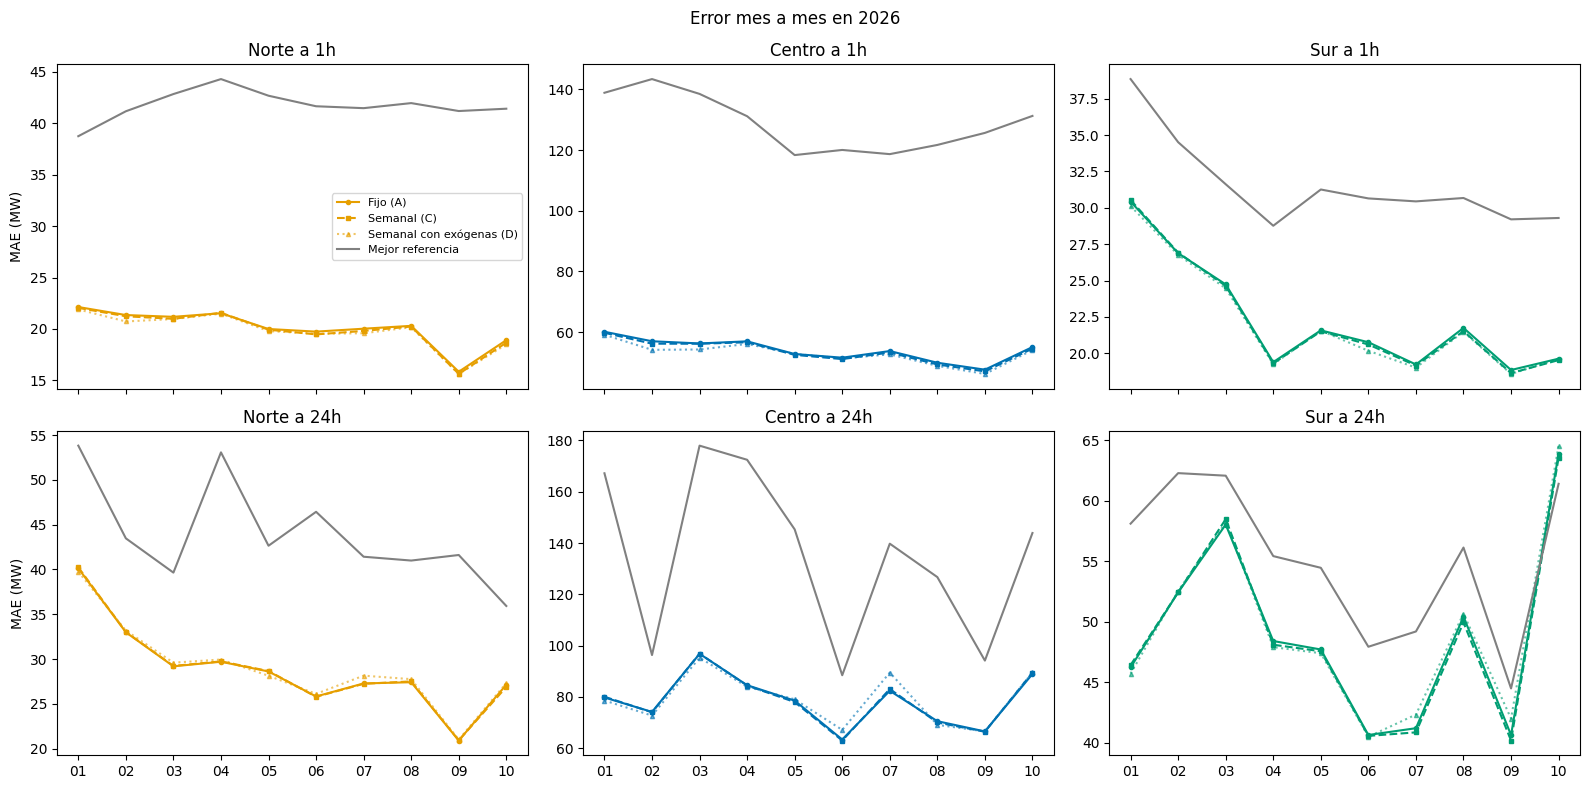

In [9]:
filas = []
for h in HORIZONTES:
    for a in AREAS:
        t = prueba(h, a)
        mes = (t["DateTime"] + HORIZONTES[h] * PASO).dt.to_period("M").astype(str).to_numpy()
        tabla = mae_por_grupo(t["real"], {"Fijo (A)": pred_adaptacion[h][("fijo", "M0")][a],
                                          "Semanal (C)": pred_adaptacion[h][("semanal", "M0")][a],
                                          "Semanal con exógenas (D)": pred_adaptacion[h][("semanal", "M3")][a],
                                          "Mejor referencia": ref_mejor(h, a)}, mes)
        filas.append(tabla.assign(Horizonte=h, Área=NOMBRES[a]).rename_axis("Mes").reset_index())
mensual = pd.concat(filas, ignore_index=True)
mensual["Mejora A (%)"] = 100 * (1 - mensual["Fijo (A)"] / mensual["Mejor referencia"])
mensual["Mejora C (%)"] = 100 * (1 - mensual["Semanal (C)"] / mensual["Mejor referencia"])
display(mensual.pivot_table(index="Mes", columns=["Horizonte", "Área"], values=["Mejora A (%)", "Mejora C (%)"]).round(1))

fig, ejes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for i, h in enumerate(HORIZONTES):
    for eje, a in zip(ejes[i], AREAS):
        d = mensual[(mensual["Horizonte"] == h) & (mensual["Área"] == NOMBRES[a])]
        for col, estilo in [("Fijo (A)", "-o"), ("Semanal (C)", "--s"), ("Semanal con exógenas (D)", ":^"),
                            ("Mejor referencia", "-")]:
            eje.plot(d["Mes"].str[5:], d[col], estilo, ms=3, label=col,
                     color="grey" if col == "Mejor referencia" else COLORES[a], alpha=1 if col != "Semanal con exógenas (D)" else 0.6)
        eje.set_title(f"{NOMBRES[a]} a {h}")
    ejes[i][0].set_ylabel("MAE (MW)")
ejes[0][0].legend(fontsize=8)
plt.suptitle("Error mes a mes en 2026")
plt.tight_layout()
plt.show()

# 7. Regímenes

Con el modelo fijo (A, M0), el fijo con clima (M1), el reentrenado cada semana (C, M0) y el reentrenado con
exógenas (D, M3). M0 y C no usan la temperatura; para la hipótesis 4 cuentan M1 y D, que sí la usan:

- **El Niño:** la categoría del ICEN definitivo del mes que se predice (septiembre y octubre todavía no tienen ICEN
  publicado y quedan aparte).
- **Horas de mayor demanda:** las cuatro horas con más demanda media de cada área en 2026, y la fracción de esas horas
  en que el modelo subestima más que el p90 del error de la mejor referencia.
- **Temperatura fuera de lo visto** (hipótesis 4): los días en que la temperatura media del área supera la máxima
  de ese mes entre 2016 y 2025. Los árboles no extrapolan, así que ahí debería fallar más.

In [10]:
ICEN_DEFINITIVO = exogenas["icen"].set_index(exogenas["icen"]["mes"].dt.to_period("M"))["icen"]


def dias_fuera_de_rango(area):
    # Días de 2026 con temperatura media mayor que la máxima del mismo mes entre 2016 y 2025
    diaria = exogenas["temperatura"].set_index("fecha_hora")[area.lower()].resample("D").mean().dropna()
    historia = diaria[diaria.index < INICIO_PRUEBA]
    tope = historia.groupby(historia.index.month).max()
    nueva = diaria[diaria.index >= INICIO_PRUEBA]
    return pd.DatetimeIndex(nueva.index[nueva.to_numpy() > nueva.index.month.map(tope).to_numpy()])


filas = []
for h in HORIZONTES:
    adelanto = HORIZONTES[h] * PASO
    for a in AREAS:
        t = prueba(h, a).reset_index(drop=True)
        objetivo = t["DateTime"] + adelanto
        preds = {"Fijo (A)": pred_adaptacion[h][("fijo", "M0")][a], "Fijo con clima (M1)": fijo[h]["M1"][a],
                 "Semanal (C)": pred_adaptacion[h][("semanal", "M0")][a],
                 "Semanal con exógenas (D)": pred_adaptacion[h][("semanal", "M3")][a], "Mejor referencia": ref_mejor(h, a)}
        pico = es_hora_pico(t["DateTime"], horas_mayor_demanda(t, adelanto), adelanto)
        fuera = objetivo.dt.normalize().isin(dias_fuera_de_rango(a)).to_numpy()
        icen_mes = objetivo.dt.to_period("M").map(ICEN_DEFINITIVO)
        regimenes = {
            "El Niño (ICEN del mes)": np.where(icen_mes.isna(), "sin ICEN publicado", categoria_icen(icen_mes).astype(str)),
            "Horas de mayor demanda": np.where(pico, "Mayor demanda", "Resto"),
            "Temperatura": np.where(fuera, "Fuera de lo visto", "Dentro de lo visto"),
        }
        for corte, etiqueta in regimenes.items():
            tabla = mae_por_grupo(t["real"], preds, etiqueta)
            for grupo, fila in tabla.iterrows():
                filas.append({"Horizonte": h, "Corte": corte, "Grupo": grupo, "Área": NOMBRES[a],
                              "Periodos": int((etiqueta == grupo).sum()), **fila.to_dict(),
                              **{f"Mejora {k} (%)": 100 * (1 - fila[k] / fila["Mejor referencia"])
                                 for k in preds if k != "Mejor referencia"}})
        for nombre in ("Fijo (A)", "Fijo con clima (M1)", "Semanal (C)", "Semanal con exógenas (D)"):
            filas.append({"Horizonte": h, "Corte": "Horas de mayor demanda",
                          "Grupo": f"Subestimación > p90 de la referencia, {nombre} (%)", "Área": NOMBRES[a],
                          "Periodos": int(pico.sum()),
                          "Fijo (A)": 100 * subestimacion_sobre_p90(t["real"], preds[nombre], preds["Mejor referencia"], pico)})
regimenes_2026 = pd.DataFrame(filas)
display(regimenes_2026.set_index(["Horizonte", "Corte", "Grupo", "Área"]).round(2))
print("Días con temperatura fuera de lo visto en 2026:", {NOMBRES[a]: len(dias_fuera_de_rango(a)) for a in AREAS})

Periodos  Fijo (A)  Fijo con clima (M1)  Semanal (C)  Semanal con exógenas (D)  \
Horizonte Corte                  Grupo                                              Área                                                                                    
1h        El Niño (ICEN del mes) cálida débil                                       Norte      2832     21.26                20.93        21.10                     20.85   
                                 cálida extraordinaria                              Norte      2976     20.16                20.15        20.02                     19.87   
                                 cálida fuerte                                      Norte      2928     19.87                19.78        19.70                     19.66   
                                 cálida moderada                                    Norte      1440     21.53                21.40        21.57                     21.49   
                                 neutra                                             Norte      1486     22.13                21.90        22.05                     21.89   
...                                                                                             ...       ...                  ...          ...                       ...   
24h       Temperatura            Fuera de lo visto                                  Sur         192     42.31                42.30        41.73                     43.02   
          Horas de mayor demanda Subestimación > p90 de la referencia, Fijo (A) (%) Sur        2312      1.86                  NaN          NaN                       NaN   
                                 Subestimación > p90 de la referencia, Fijo con ... Sur        2312      2.21                  NaN          NaN                       NaN   
                                 Subestimación > p90 de la referencia, Semanal (... Sur        2312      2.03                  NaN          NaN                       NaN   
                                 Subestimación > p90 de la referencia, Semanal c... Sur        2312      2.25                  NaN          NaN                       NaN   

                                                                                           Mejor referencia  Mejora Fijo (A) (%)  Mejora Fijo con clima (M1) (%)  \
Horizonte Corte                  Grupo                                              Área                                                                           
1h        El Niño (ICEN del mes) cálida débil                                       Norte             42.06                49.45                           50.24   
                                 cálida extraordinaria                              Norte             41.72                51.68                           51.72   
                                 cálida fuerte                                      Norte             42.18                52.90                           53.12   
                                 cálida moderada                                    Norte             44.31                51.41                           51.70   
                                 neutra                                             Norte             38.75                42.89                           43.48   
...                                                                                                     ...                  ...                             ...   
24h       Temperatura            Fuera de lo visto                                  Sur               45.18                 6.35                            6.38   
          Horas de mayor demanda Subestimación > p90 de la referencia, Fijo (A) (%) Sur                 NaN                  NaN                             NaN   
                                 Subestimación > p90 de la referencia, Fijo con ... Sur                 NaN                  NaN                             NaN   
                                 Sube

Días con temperatura fuera de lo visto en 2026: {'Norte': 105, 'Centro': 91, 'Sur': 4}


# 8. Diagnóstico

Dos semanas de julio de 2026, en el pico de El Niño, en el Norte: lo real, el modelo fijo, el reentrenado cada semana
y la mejor referencia, a 1 h y a 24 h. Y los residuos del modelo fijo en toda la prueba.

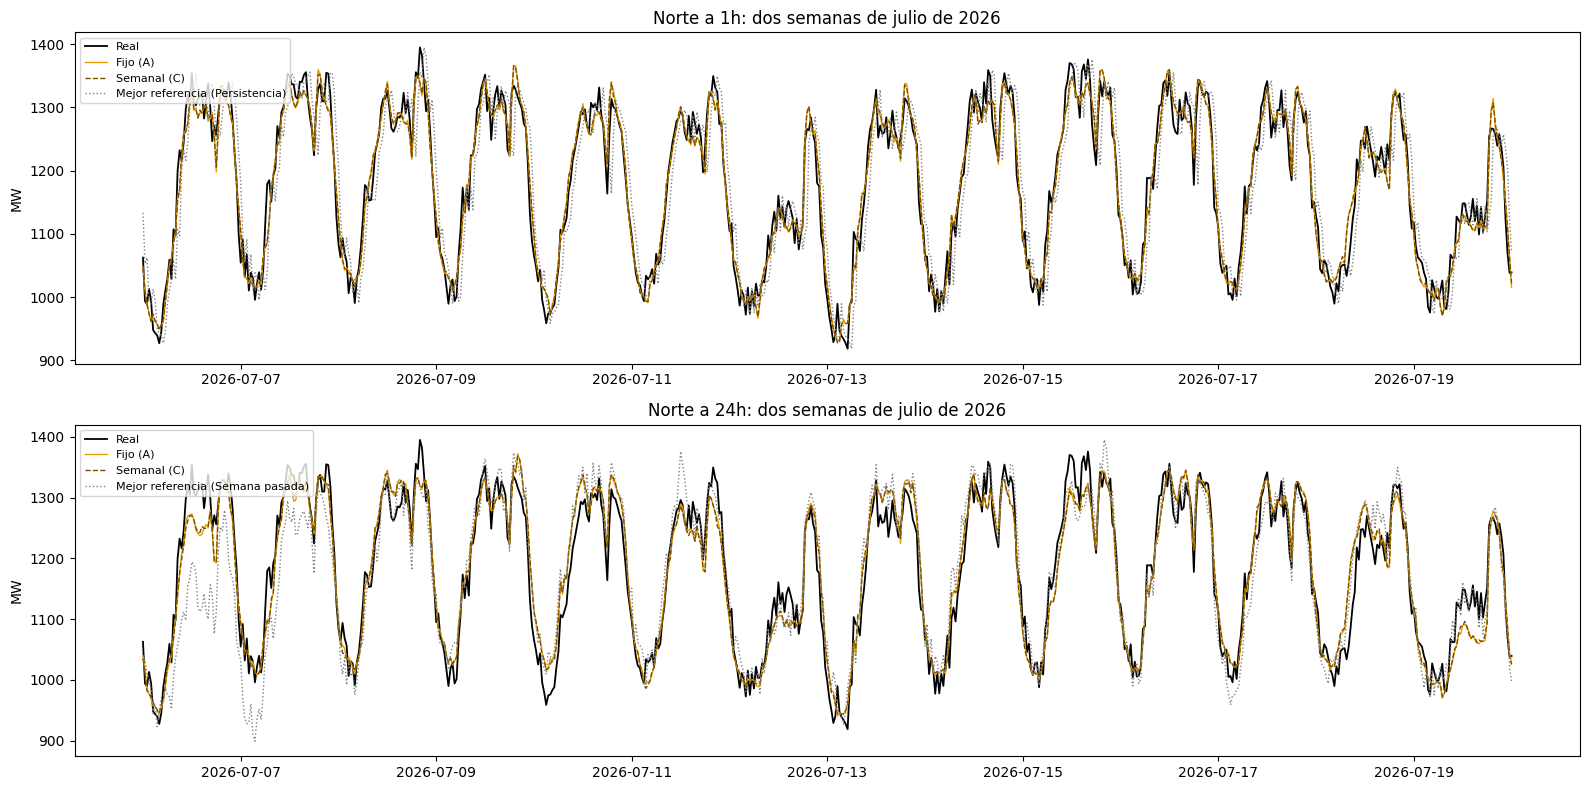

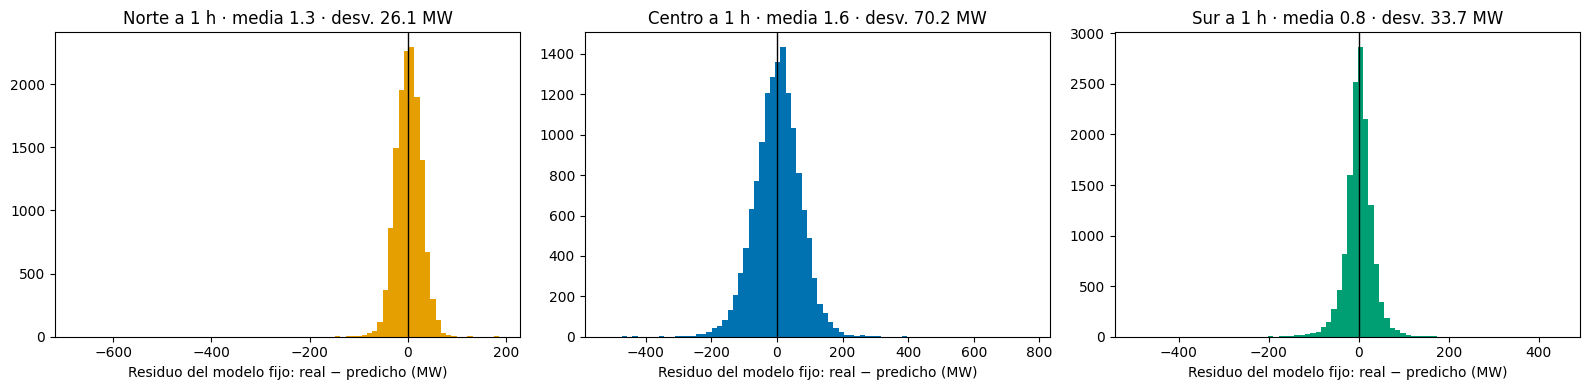

In [11]:
ventana = (pd.Timestamp("2026-07-06"), pd.Timestamp("2026-07-20"))
fig, ejes = plt.subplots(2, 1, figsize=(16, 8))
for eje, h in zip(ejes, HORIZONTES):
    t = prueba(h, "NORTE").reset_index(drop=True)
    objetivo = t["DateTime"] + HORIZONTES[h] * PASO
    filtro = objetivo.between(*ventana).to_numpy()
    eje.plot(objetivo[filtro], t["real"][filtro], color="black", lw=1.3, label="Real")
    eje.plot(objetivo[filtro], pred_adaptacion[h][("fijo", "M0")]["NORTE"][filtro], color=COLORES["NORTE"], lw=1,
             label="Fijo (A)")
    eje.plot(objetivo[filtro], pred_adaptacion[h][("semanal", "M0")]["NORTE"][filtro], "--", color="#7a4f00", lw=1,
             label="Semanal (C)")
    eje.plot(objetivo[filtro], ref_mejor(h, "NORTE")[filtro], ":", color="grey", lw=1,
             label=f"Mejor referencia ({NOMBRES_REF[MEJOR_REF[h]['NORTE']]})")
    eje.set_ylabel("MW")
    eje.set_title(f"Norte a {h}: dos semanas de julio de 2026")
    eje.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, a in zip(ejes, AREAS):
    t = prueba("1h", a)
    residuo = t["real"].to_numpy() - pred_adaptacion["1h"][("fijo", "M0")][a]
    eje.hist(residuo, bins=80, color=COLORES[a])
    eje.axvline(0, color="black", lw=1)
    eje.set(title=f"{NOMBRES[a]} a 1 h · media {residuo.mean():.1f} · desv. {residuo.std():.1f} MW",
            xlabel="Residuo del modelo fijo: real − predicho (MW)")
plt.tight_layout()
plt.show()

# 9. Las hipótesis, una por una

Se evalúan tal como quedaron escritas en el notebook 02 (§12), antes de esta corrida.

In [12]:
fr = frente_referencias.set_index(["Horizonte", "Área", "Método"])
fijo_A = f"{ELEGIDO}, fijo (A)"
ab = ablacion.set_index(["Horizonte", "Contraste", "Área"])
ef = efectos_adaptacion.set_index(["Horizonte", "Contraste", "Área"])


def gana(h, a):
    return fr.loc[(h, NOMBRES[a], fijo_A), "Δ MAE vs. referencia (MW)"] < 0


def texto_ic(tabla, clave):
    fila = tabla.loc[clave]
    return f"{fila['Δ MAE (MW)']:.2f} MW (IC {fila['IC 95 % bajo']:.2f} a {fila['IC 95 % alto']:.2f})"


mejora_norte = fr.loc[("1h", "Norte", fijo_A), "Mejora vs. mejor referencia (%)"]
c_a_norte = ef.loc[("1h", "Reentrenar sin exógenas (C − A)", "Norte")]
filas = [
    {"Hipótesis": "1a. A le gana a la mejor referencia a 1 h en las tres áreas",
     "¿Se cumple?": all(gana("1h", a) for a in AREAS),
     "Evidencia": ", ".join(f"{NOMBRES[a]} {fr.loc[('1h', NOMBRES[a], fijo_A), 'Mejora vs. mejor referencia (%)']:.1f} %" for a in AREAS)},
    {"Hipótesis": "1b. En el Norte la mejora a 1 h baja respecto de 2025 (49 %) pero queda sobre 25 %",
     "¿Se cumple?": 25 < mejora_norte < 49, "Evidencia": f"Norte {mejora_norte:.1f} %"},
    {"Hipótesis": "1c. A 24 h le gana en el Centro y el Norte",
     "¿Se cumple?": gana("24h", "CENTRO") and gana("24h", "NORTE"),
     "Evidencia": ", ".join(f"{NOMBRES[a]} {fr.loc[('24h', NOMBRES[a], fijo_A), 'Mejora vs. mejor referencia (%)']:.1f} %" for a in AREAS)},
    {"Hipótesis": "2. Reentrenar cada semana (C − A) en el Norte a 1 h: negativo y su IC no cruza el cero",
     "¿Se cumple?": c_a_norte["IC 95 % alto"] < 0, "Evidencia": texto_ic(ef, ("1h", "Reentrenar sin exógenas (C − A)", "Norte"))},
    {"Hipótesis": "3. M3 − M0 a 1 h no se distingue de cero en ninguna área",
     "¿Se cumple?": not any(ab.loc[("1h", "Todas (M3 − M0)", NOMBRES[a]), "Distinguible"] for a in AREAS),
     "Evidencia": "; ".join(f"{NOMBRES[a]} {texto_ic(ab, ('1h', 'Todas (M3 − M0)', NOMBRES[a]))}" for a in AREAS)},
    {"Hipótesis": "4. El clima ayuda a 24 h en el Centro (M1 − M0 negativo, IC bajo cero)",
     "¿Se cumple?": ab.loc[("24h", "Clima (M1 − M0)", "Centro"), "IC 95 % alto"] < 0,
     "Evidencia": texto_ic(ab, ("24h", "Clima (M1 − M0)", "Centro"))},
    {"Hipótesis": "5. El Niño no mejora en ningún horizonte ni área (M2 − M1 nunca con IC bajo cero)",
     "¿Se cumple?": not any(ab.loc[(h, "El Niño (M2 − M1)", NOMBRES[a]), "IC 95 % alto"] < 0 for h in HORIZONTES for a in AREAS),
     "Evidencia": "; ".join(f"{h} {NOMBRES[a]} {ab.loc[(h, 'El Niño (M2 − M1)', NOMBRES[a]), 'Δ MAE (MW)']:.2f}"
                           for h in HORIZONTES for a in AREAS)},
]
hipotesis = pd.DataFrame(filas)
hipotesis["¿Se cumple?"] = hipotesis["¿Se cumple?"].map({True: "Sí", False: "No"})
with pd.option_context("display.max_colwidth", 200):
    display(hipotesis.set_index("Hipótesis"))

,¿Se cumple?,Evidencia
Hipótesis,,
1a. A le gana a la mejor referencia a 1 h en las tres áreas,Sí,"Norte 51.7 %, Centro 57.9 %, Sur 29.1 %"
1b. En el Norte la mejora a 1 h baja respecto de 2025 (49 %) pero queda sobre 25 %,No,Norte 51.7 %
1c. A 24 h le gana en el Centro y el Norte,Sí,"Norte 34.5 %, Centro 42.2 %, Sur 11.9 %"
2. Reentrenar cada semana (C − A) en el Norte a 1 h: negativo y su IC no cruza el cero,Sí,-0.14 MW (IC -0.19 a -0.09)
3. M3 − M0 a 1 h no se distingue de cero en ninguna área,No,Norte -0.10 MW (IC -0.19 a 0.00); Centro -0.53 MW (IC -0.78 a -0.27); Sur -0.02 MW (IC -0.11 a 0.06)
"4. El clima ayuda a 24 h en el Centro (M1 − M0 negativo, IC bajo cero)",No,1.35 MW (IC 0.10 a 2.97)
5. El Niño no mejora en ningún horizonte ni área (M2 − M1 nunca con IC bajo cero),Sí,1h Norte -0.00; 1h Centro -0.09; 1h Sur -0.02; 24h Norte -0.03; 24h Centro -0.01; 24h Sur 0.83


# 10. Guardar

Las predicciones de 2026 de cada política y variante, por área y horizonte, quedan en `reportes/sein/prueba_2026/`
para la app y el paper, junto con las tablas de este notebook. La corrida rápida escribe en `prueba_2026_rapido/`.

In [13]:
carpeta = RAIZ / "reportes" / "sein" / ("prueba_2026_rapido" if RAPIDO else "prueba_2026")
carpeta.mkdir(parents=True, exist_ok=True)
for h in HORIZONTES:
    for a in AREAS:
        t = prueba(h, a)
        salida = t[["DateTime", "real", *REFERENCIAS]].assign(
            **{f"{p}_{v}": pred[a] for (p, v), pred in pred_adaptacion[h].items()},
            **{f"alternativo_{ALTERNATIVO.split()[0].lower()}": alternativo[h][a]})
        salida.to_csv(carpeta / f"predicciones_{h}_{a.lower()}.csv", index=False)
for nombre, tabla in {"frente_referencias": frente_referencias, "ablacion": ablacion, "adaptacion": adaptacion,
                      "efectos_adaptacion": efectos_adaptacion, "mensual": mensual, "regimenes": regimenes_2026,
                      "hipotesis": hipotesis}.items():
    tabla.to_csv(carpeta / f"{nombre}.csv", index=False)
print("Predicciones y tablas en", carpeta)

Predicciones y tablas en /content/datos/reportes/sein/prueba_2026


# Conclusiones

La prueba se corrió una sola vez con lo fijado en el commit `cadf68e`. La sesión de Colab se cayó tres veces cuando la
laptop que la mantenía viva se suspendió; la corrida se retomó con la caché de bloques (#27), sin cambiar código ni
elecciones. Por eso algunos bloques de la §5 muestran "0.0 min": salieron de la caché.

**1. El método se sostiene fuera de lo visto.** Con El Niño extraordinario (ICEN de 3.98 en agosto) y la demanda del
Norte creciendo hasta 17 % sobre 2025, el modelo fijo, entrenado hasta 2025 y sin tocarlo durante 2026, le gana a la
mejor referencia en las tres áreas y los dos horizontes, con intervalos lejos del cero. A 1 h: 51.7 % en el Norte,
57.9 % en el Centro y 29.1 % en el Sur (MAE de 20.2, 54.1 y 22.4 MW; MAPE de 1.8, 1.25 y 1.24 %). A 24 h: 34.5,
42.2 y 11.9 %. La mejora es mayor que en 2025 en cinco de los seis casos (salvo el Sur a 24 h): predecir la razón con
la media de 24 h absorbe el salto de nivel.

**2. No se degrada a medida que El Niño se intensifica.** La mejora del Norte a 1 h pasa de 43 % en enero a entre 51
y 53 % de abril a agosto, y a 62 % en septiembre. Los días con temperatura por encima de todo lo visto en 2016-2025
(105 en el Norte, 91 en el Centro) no son peores para el modelo a 1 h. El único mes, área y horizonte en que pierde
es el Sur a 24 h en octubre (−4 %).

**3. El XGBoost global empata, como en 2025.** A 1 h queda apenas por encima (52.4, 58.5 y 29.2 %) y a 24 h apenas
por debajo. Elegir uno u otro no cambia ninguna conclusión.

**4. Reentrenar ayuda, pero poco.** Reentrenar cada semana (41 veces) baja el error a 1 h en las tres áreas, ahora
también en el Norte (−0.14 MW, IC −0.19 a −0.09), donde en 2025 no se distinguía de cero. Con exógenas el efecto
llega a −0.60 MW en el Centro, y sin la variable de fallas a −0.70 MW: cerca del 1 % del error. A 24 h, reentrenar
sin exógenas no se distingue de no hacerlo. Reentrenar solo cuando cambia la alerta de ENFEN (4 veces) es peor que
cada semana en el Centro y el Sur, y sumarla a la semanal no agrega nada.

**5. Las exógenas: casi nada a 1 h, y en contra a 24 h.** A 1 h, el clima mejora el Centro en 0.46 MW (IC −0.71 a
−0.20); en el Norte y el Sur no se distingue de cero. A 24 h el clima **empeora** el pronóstico en el Norte (+0.42 MW)
y en el Centro (+1.35 MW, IC 0.10 a 2.97). Es el riesgo que se declaró antes de la prueba: temperaturas fuera del
rango de entrenamiento, sumadas a un pronóstico de temperatura simulado con error. El Niño no mejora en ningún caso
y empeora el Sur a 24 h (+0.83 MW). Reentrenar cada semana compensa parte de ese daño (D − B: −0.87 MW en el Centro a
24 h).

**Las hipótesis** (tabla de la §9):

- **H1 se cumple en lo esencial:** gana en las tres áreas a 1 h y en el Centro y el Norte a 24 h (también en el Sur).
  No se cumplió que la mejora del Norte *bajara*: subió de 49 a 52 %.
- **H2 se cumple:** reentrenar cada semana en el Norte se distingue de cero, aunque el efecto es pequeño.
- **H3 no se cumple:** a 1 h las exógenas sí ayudan algo en el Centro (−0.53 MW con M3), por el clima.
- **H4 no se cumple, en sentido contrario:** el clima empeora el Centro a 24 h. Lo observado es el riesgo que
  acompañaba a la hipótesis.
- **H5 se cumple:** El Niño no mejora en ningún horizonte ni área.

**Lo que se lleva el paper.** Lo que sostiene el pronóstico durante un evento extraordinario es la metodología:
predecir la razón con la media de 24 h y medirse contra la mejor referencia ingenua. Reentrenar cada semana y sumar
exógenas aportan como mucho alrededor de 1 %, y con temperaturas nunca vistas el clima puede empeorar el pronóstico
del día siguiente. Para el operador, la recomendación es el modelo en razón reentrenado cada semana con el clima a
1 h, y sin exógenas a 24 h, donde reentrenarlo da igual.